# Week 8: Forecasting and Applied Predictive AI

So far we have predicted a category (tumor or not, which digit). Forecasting predicts a number in the future from a history of past values, ordered in time.

**Key terms for today**
- Time series: values recorded at regular time intervals (monthly passengers, daily stock price)
- Trend: the long-run direction (up, down, flat). Seasonality is a pattern that repeats on a fixed cycle. Noise is the rest.
- Forecast horizon: how far into the future we predict. Longer horizons are harder.
- Lag: a past value used as an input (lag 1 is yesterday)
- RNN and LSTM: neural networks built for sequences (Step 3)

**One rule changes from earlier weeks: never shuffle time series data.** Training data must come before test data in time, otherwise the model sees the future (data leakage).


In [1]:
import os, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler

import keras
from keras import layers

pd.set_option('display.float_format', '{:,.2f}'.format)
print('Libraries loaded.')

Libraries loaded.


---
## Step 0 - Load and Plot the Series

**Demo dataset:** monthly airline passengers, 1949 to 1960. It has a clear upward trend and a repeating yearly pattern.

Observations: 144  From 1949-01-01 to 1960-12-01


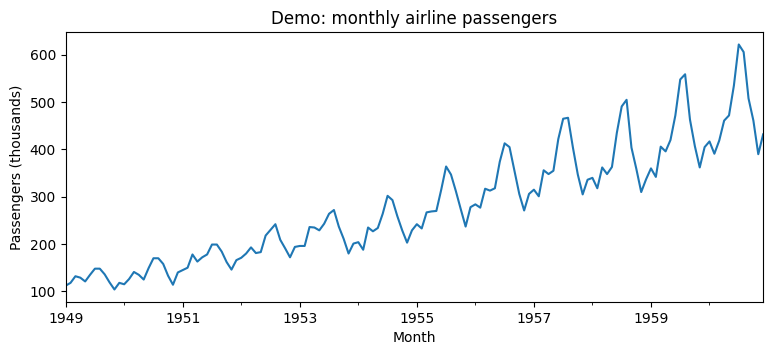

In [2]:
air_url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'
series_d = pd.read_csv(air_url, parse_dates=['Month'], index_col='Month')['Passengers']

print('Observations:', len(series_d), ' From', series_d.index.min().date(), 'to', series_d.index.max().date())

plt.figure(figsize=(9, 3.5))
series_d.plot()
plt.title('Demo: monthly airline passengers')
plt.ylabel('Passengers (thousands)')
plt.show()

### Your Turn - Load your series

**Your dataset: Apple (AAPL) daily stock data**, about 500 trading days from February 2015 to February 2017. Pick what to forecast:
- `'AAPL.Close'`: the daily closing price
- `'AAPL.Volume'`: the number of shares traded that day

TODO: set `TARGET` below, then run the cell.

In [ ]:
stock_url = 'https://raw.githubusercontent.com/plotly/datasets/master/finance-charts-apple.csv'
stock_df = pd.read_csv(stock_url, parse_dates=['Date'], index_col='Date')

TARGET = None   # TODO: choose 'AAPL.Close' or 'AAPL.Volume'
assert TARGET is not None, 'Set TARGET above first, then re-run this cell.'

series_y = stock_df[TARGET]
print('Observations:', len(series_y), ' From', series_y.index.min().date(), 'to', series_y.index.max().date())

plt.figure(figsize=(9, 3.5))
series_y.plot()
plt.title(f'Your data: {TARGET}')
plt.show()

**Your answers:**
1. Describe your plot: is there a clear trend? A repeating pattern?
2. Compare it to the airline plot. Which series looks easier to predict, and why?

---
## Step 1 - Time-Ordered Split and Baselines

**Split by time:** train on the earlier part, test on the final stretch. Never use a random split.

Before any machine learning, set simple baselines. If a fancy model cannot beat these, it is not worth using (same idea as the do-nothing baseline from Week 6).

- Naive: predict that every future value equals the last observed value
- Moving average: predict the average of the most recent window

We score with **MAE** (average miss, in the original units) and **MAPE** (average miss as a percent of the actual value).

,MAE,MAPE (%)
Moving average,77.83,15.47
Naive (last value),115.25,23.58


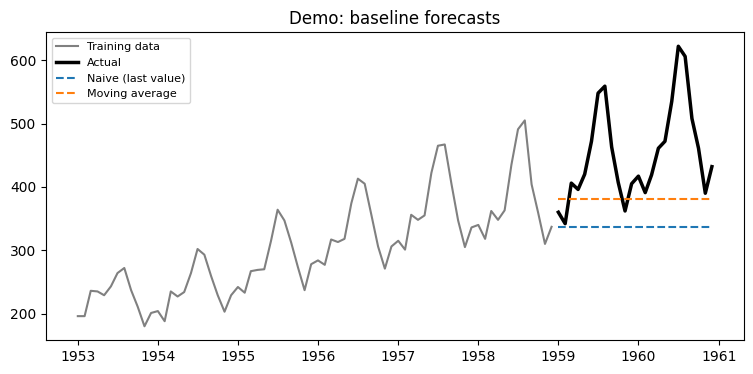

In [3]:
def mae(actual, pred):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(pred))))

def mape(actual, pred):
    actual = np.asarray(actual)
    return float(np.mean(np.abs((actual - np.asarray(pred)) / actual)) * 100)

def baseline_forecasts(train, steps, window):
    return {
        'Naive (last value)': np.repeat(train.iloc[-1], steps),
        'Moving average': np.repeat(train.iloc[-window:].mean(), steps),
    }

def score_table(actual, forecasts):
    rows = {name: {'MAE': mae(actual, f), 'MAPE (%)': mape(actual, f)} for name, f in forecasts.items()}
    return pd.DataFrame(rows).T.sort_values('MAE')

def plot_forecasts(train, test, forecasts, title):
    context = train.iloc[-max(3 * len(test), 36):]
    plt.figure(figsize=(9, 4))
    plt.plot(context.index, context.values, color='gray', label='Training data')
    plt.plot(test.index, test.values, color='black', linewidth=2.5, label='Actual')
    for name, f in forecasts.items():
        plt.plot(test.index, f, linestyle='--', label=name)
    plt.title(title)
    plt.legend(fontsize=8)
    plt.show()

TEST_D = 24     # hold out the final 24 months
train_d, test_d = series_d.iloc[:-TEST_D], series_d.iloc[-TEST_D:]

forecasts_d = baseline_forecasts(train_d, TEST_D, window=12)
display(score_table(test_d, forecasts_d))
plot_forecasts(train_d, test_d, forecasts_d, 'Demo: baseline forecasts')

### Your Turn - Baselines on your series

TODO: set two values.
- `TEST_DAYS`: how many trading days at the end to hold out and forecast (try 5, 20, 60)
- `WINDOW`: how many recent days the moving average uses (try 5, 20, 60)

In [ ]:
TEST_DAYS = None   # TODO: days to hold out. Try 5, 20, 60.
WINDOW = None      # TODO: moving average window in days. Try 5, 20, 60.
assert TEST_DAYS is not None and WINDOW is not None, 'Set TEST_DAYS and WINDOW above first, then re-run this cell.'

train_y, test_y = series_y.iloc[:-TEST_DAYS], series_y.iloc[-TEST_DAYS:]

forecasts_y = baseline_forecasts(train_y, TEST_DAYS, window=WINDOW)
display(score_table(test_y, forecasts_y))
plot_forecasts(train_y, test_y, forecasts_y, f'Your data: baseline forecasts ({TARGET})')

**Your answers:**
1. Which baseline has the lower MAE on your data? Why might that be?
2. Change `TEST_DAYS` or `WINDOW` and re-run. What happens to the errors?

---
## Step 2 - Forecasting with Lag Features

To use an ordinary model (the same scikit-learn tools as earlier weeks), we turn the series into a table: each row's features are the previous `n` values (the lags), and the target is the current value.

To forecast several steps ahead, the model predicts one step, then feeds that prediction back in as a lag to predict the next step. Mistakes can therefore compound.

Two things to watch:
- **Number of lags.** The model only knows what its lags show it.
- **Model type.** A linear model can extend a trend. A random forest can only output values it has seen in training, so it struggles when the series trends beyond the training range.

In [4]:
def make_lags(series, n_lags):
    df = pd.DataFrame({'y': series.values}, index=series.index)
    for k in range(1, n_lags + 1):
        df[f'lag_{k}'] = series.shift(k).values
    return df.dropna()

def get_model(name):
    if name == 'linear':
        return LinearRegression()
    if name == 'forest':
        return RandomForestRegressor(n_estimators=200, random_state=42)
    raise ValueError("MODEL must be 'linear' or 'forest'")

def ml_forecast(train, steps, n_lags, model_name):
    data = make_lags(train, n_lags)
    model = get_model(model_name).fit(data.drop(columns='y').values, data['y'].values)
    history = list(train.values[-n_lags:])
    preds = []
    for _ in range(steps):
        x = np.array(history[-n_lags:][::-1]).reshape(1, -1)   # lag_1 is the most recent value
        p = model.predict(x)[0]
        preds.append(p)
        history.append(p)
    return np.array(preds)

# Demo: 3 lags vs 12 lags, linear vs forest
rows = []
for n in [3, 12]:
    for m in ['linear', 'forest']:
        rows.append({'model': m, 'lags': n, 'MAE': mae(test_d, ml_forecast(train_d, TEST_D, n, m))})
display(pd.DataFrame(rows))

,model,lags,MAE
0,linear,3,136.84
1,forest,3,85.73
2,linear,12,21.45
3,forest,12,46.62


,MAE,MAPE (%)
"Linear, 12 lags",21.45,4.82
Moving average,77.83,15.47
Naive (last value),115.25,23.58


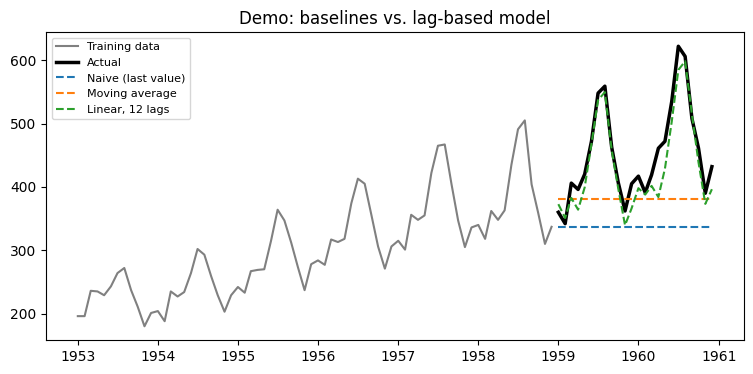

In [5]:
forecasts_d['Linear, 12 lags'] = ml_forecast(train_d, TEST_D, 12, 'linear')
display(score_table(test_d, forecasts_d))
plot_forecasts(train_d, test_d, forecasts_d, 'Demo: baselines vs. lag-based model')

With 12 lags the model sees a full year of history and does far better than with 3 lags. More history helps only up to the point where the model has seen the pattern it needs.

### Your Turn - Lag-based forecast on your series

TODO: set two values.
- `N_LAGS`: how many past days the model sees (try 1, 5, 20)
- `MODEL`: `'linear'` or `'forest'`

Each time you re-run with new values, a new row is added to the table so you can compare attempts. (Re-run the Step 1 cell to reset the table.)

In [6]:
N_LAGS = None   # TODO: number of past values. Try 1, 5, 20.
MODEL = None    # TODO: 'linear' or 'forest'
assert N_LAGS is not None and MODEL is not None, 'Set N_LAGS and MODEL above first, then re-run this cell.'

forecasts_y[f'{MODEL}, {N_LAGS} lags'] = ml_forecast(train_y, TEST_DAYS, N_LAGS, MODEL)
display(score_table(test_y, forecasts_y))
plot_forecasts(train_y, test_y, forecasts_y, f'Your data: baselines vs. lag-based model ({TARGET})')

AssertionError: Set N_LAGS and MODEL above first, then re-run this cell.

**Your answers:**
1. Did any setting beat the best baseline from Step 1? By how much?
2. Try both `'linear'` and `'forest'`. How do their forecast lines look different on the plot, and why?

---
## Step 3 - Neural Sequence Models: RNN and LSTM

The lag approach treats each lag as a separate column and has no built-in idea of order. **Recurrent neural networks (RNNs)** are designed for sequences. An RNN reads the series one step at a time and carries a hidden state, a running memory, forward from step to step. It is trained with backpropagation, just like the networks from Week 7.

**The problem with plain RNNs:** over long sequences the learning signal fades (the vanishing gradient problem), so they forget what happened many steps ago.

**LSTM (Long Short-Term Memory)** fixes this by adding a separate memory cell and three gates that learn what to forget, what to store, and what to output. It can hold on to information for much longer. LSTMs and related models are behind a lot of applied forecasting and speech work.

**Practical points for the code below**
- The input shape is (samples, time steps, features). One sample is a window of the last `seq_len` values.
- Neural networks train poorly on raw values, so we scale to 0 to 1. **The scaler is fit on training data only**, otherwise test information leaks in.
- We forecast the same way as Step 2: predict one step, feed it back, repeat.
- Results can vary a little from run to run, since training starts from random weights. We set a seed, but small differences between computers are normal.

,MAE,MAPE (%)
"Linear, 12 lags",21.45,4.82
"RNN, 12 steps",44.29,9.54
"LSTM, 12 steps",66.49,14.33
Moving average,77.83,15.47
Naive (last value),115.25,23.58


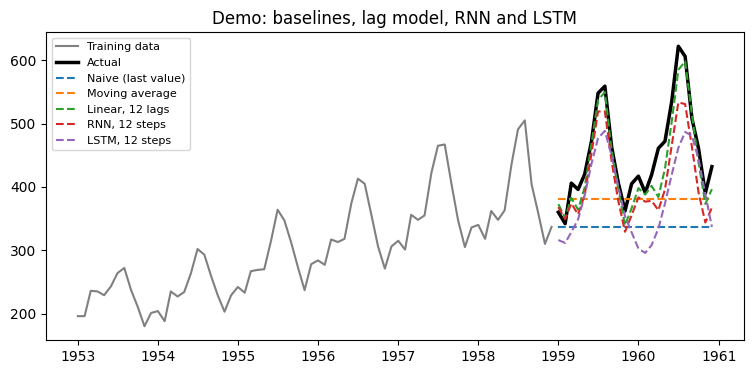

In [7]:
def nn_forecast(train, steps, seq_len, nn_type, epochs=100, units=32):
    keras.utils.set_random_seed(42)

    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(train.values.reshape(-1, 1)).ravel()   # fit on training data only

    # Each sample: a window of seq_len values. Target: the value that comes right after.
    X = np.array([scaled[i:i + seq_len] for i in range(len(scaled) - seq_len)])[..., None]
    y = scaled[seq_len:]

    recurrent = layers.SimpleRNN(units) if nn_type == 'rnn' else layers.LSTM(units)
    model = keras.Sequential([keras.Input(shape=(seq_len, 1)), recurrent, layers.Dense(1)])
    model.compile(optimizer='adam', loss='mse')
    model.fit(X, y, epochs=epochs, batch_size=16, verbose=0)

    window = list(scaled[-seq_len:])
    preds = []
    for _ in range(steps):
        p = model.predict(np.array(window[-seq_len:]).reshape(1, seq_len, 1), verbose=0)[0, 0]
        preds.append(p)
        window.append(p)
    return scaler.inverse_transform(np.array(preds).reshape(-1, 1)).ravel()

# Demo: an RNN and an LSTM, each looking at the last 12 months (takes about 30 seconds)
forecasts_d['RNN, 12 steps'] = nn_forecast(train_d, TEST_D, seq_len=12, nn_type='rnn', epochs=150)
forecasts_d['LSTM, 12 steps'] = nn_forecast(train_d, TEST_D, seq_len=12, nn_type='lstm', epochs=150)

display(score_table(test_d, forecasts_d))
plot_forecasts(train_d, test_d, forecasts_d, 'Demo: baselines, lag model, RNN and LSTM')

Compare the rows. Neural sequence models are not automatically better than a simple linear model, especially on a small series like this one (about 120 training points). They shine with lots of data and complex patterns, and they cost more to train and are harder to explain. This connects back to Week 6: match the model to the problem, and always compare against a simple baseline.

### Your Turn - RNN and LSTM on your series

TODO: set two values.
- `NN_TYPE`: `'rnn'` or `'lstm'`
- `SEQ_LEN`: how many past days the network reads (try 5, 10, 20)

Training takes about 10 seconds. Like Step 2, each run adds a row to the table.

In [ ]:
NN_TYPE = None   # TODO: 'rnn' or 'lstm'
SEQ_LEN = None   # TODO: window length in days. Try 5, 10, 20.
assert NN_TYPE in ('rnn', 'lstm') and SEQ_LEN is not None, "Set NN_TYPE ('rnn' or 'lstm') and SEQ_LEN above first, then re-run this cell."

forecasts_y[f'{NN_TYPE.upper()}, {SEQ_LEN} steps'] = nn_forecast(train_y, TEST_DAYS, SEQ_LEN, NN_TYPE, epochs=30)
display(score_table(test_y, forecasts_y))
plot_forecasts(train_y, test_y, forecasts_y, f'Your data: all methods so far ({TARGET})')

**Your answers:**
1. Did your RNN or LSTM beat the naive baseline? Did it beat your best lag-based model from Step 2?
2. Run both `'rnn'` and `'lstm'` with the same `SEQ_LEN`. Is there a clear winner? Given what you read about LSTMs, would you expect one on a series this short?

---
## Step 4 - Forecast Horizon

The further ahead we forecast, the less we know. We score only the first `h` steps of each forecast to see how error changes with the horizon.

In [ ]:
horizons_d = [1, 3, 6, 12, 24]
rows = {h: {name: mae(test_d.iloc[:h], f[:h]) for name, f in forecasts_d.items()} for h in horizons_d}
horizon_table_d = pd.DataFrame(rows).T
horizon_table_d.index.name = 'horizon (months)'
display(horizon_table_d)

horizon_table_d.plot(marker='o', figsize=(8, 4))
plt.ylabel('MAE')
plt.title('Demo: error by forecast horizon')
plt.legend(fontsize=8)
plt.show()

Errors generally grow as the horizon gets longer, and the naive forecast degrades fastest because it ignores the trend. A forecast for next month and a forecast for two years out are different problems.

### Your Turn - Error by horizon on your series

TODO: set `HORIZONS`, a list of how many days ahead to score. Each value must be no larger than `TEST_DAYS`. Example: `[1, 5, 10, 20]`

In [ ]:
HORIZONS = None   # TODO: a list such as [1, 5, 10, 20], each <= TEST_DAYS
assert HORIZONS is not None, 'Set HORIZONS above first, then re-run this cell.'
assert max(HORIZONS) <= TEST_DAYS, 'Every horizon must be <= TEST_DAYS.'

rows = {h: {name: mae(test_y.iloc[:h], f[:h]) for name, f in forecasts_y.items()} for h in HORIZONS}
horizon_table_y = pd.DataFrame(rows).T
horizon_table_y.index.name = 'horizon (days)'
display(horizon_table_y)

horizon_table_y.plot(marker='o', figsize=(8, 4))
plt.ylabel('MAE')
plt.title(f'Your data: error by forecast horizon ({TARGET})')
plt.legend(fontsize=8)
plt.show()

**Your answers:**
1. Does error grow as the horizon grows on your data? Is the growth steady or jumpy?
2. At the shortest horizon, which method is best? At the longest? Why might the winner change?

---
## Step 5 - In-Class Activity (IC-7): Can We Trust This Forecast?

Three short tasks. Use the Your Turn cells above and change one setting at a time. Write one or two sentences for each.

**Task 1 (about 4 minutes).** Set `TARGET = 'AAPL.Close'`, `TEST_DAYS = 20`, `WINDOW = 5`, `N_LAGS = 5`, `MODEL = 'linear'`, `NN_TYPE = 'lstm'`, `SEQ_LEN = 5`. Run Steps 1 through 4 in order. Which method has the lowest MAE? Did the LSTM beat the naive baseline?

**Task 2 (about 3 minutes).** Change exactly one thing: switch `NN_TYPE` to `'rnn'`, or change `SEQ_LEN` to 20, or change `TEST_DAYS` to 60 (re-run from Step 1 if you change `TEST_DAYS`). Re-run the affected cells. What changed in the table and plot?

**Task 3 (about 2 minutes).** A friend wants to use your best model to decide when to buy and sell stock. Using your MAE numbers and the naive baseline as evidence, would you recommend it? Why or why not?

**Your answers:**

Task 1:

Task 2:

Task 3:

**To submit for the in-class activity:** upload a screenshot of your Step 3 table along with your three written answers to the IC-7 module.

---
# Assignment 7 - Forecast, Compare, and Explain

Run the notebook from the top with your chosen settings first. Write your own explanations; answers that only restate numbers will not get full credit.

## Task 1 - Window length experiment

Compare the RNN and LSTM across several window lengths on the same train/test split. This runs 8 or more models, so it takes about a minute.

TODO: set `seq_len_options` to a list of at least four values (for example `[3, 5, 10, 20]`).

In [ ]:
seq_len_options = None   # TODO: a list of at least 4 window lengths, e.g. [3, 5, 10, 20]
assert seq_len_options is not None and len(seq_len_options) >= 4, 'Set seq_len_options to a list of at least 4 values first.'

rows = []
for nn_type in ['rnn', 'lstm']:
    for n in seq_len_options:
        preds = nn_forecast(train_y, TEST_DAYS, n, nn_type, epochs=30)
        rows.append({'model': nn_type.upper(), 'window': n, 'MAE': mae(test_y, preds)})

results = pd.DataFrame(rows)
display(results.pivot(index='window', columns='model', values='MAE'))
print('Naive baseline MAE:', round(mae(test_y, forecasts_y['Naive (last value)']), 3))

**Task 1 answer.** Which model and window length was best? Did any beat the naive baseline? How did window length affect each model? Does the RNN versus LSTM result match what you expected from how they work?

**Your answer:**

## Task 2 - Reflection

In 6 to 8 sentences:
1. Why is a random train/test split a mistake for time series? Use the term data leakage. Where in the neural network code did we have to be careful about leakage?
2. The airline data was easier to forecast than the stock data. Explain why, using the words trend, seasonality, and noise.
3. Based on your results, when would you use an LSTM instead of a simple lag-based model or a naive baseline, and when would you not?

**Your answer:**